In [1]:
# ============================================================
# 01_eda.ipynb | CELL 1 — Install Libraries, Setup & FAERS Download
# ============================================================

import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

# ── Install Required Libraries ───────────────────────────────
print("Installing libraries...")
#Only for dataset analyzing and EDA
install("kaggle")
install("pandas")
install("numpy")
install("matplotlib")
install("seaborn")
#only for ML training
install("scikit-learn")
install("imbalanced-learn")   # SMOTE
install("xgboost")
install("transformers")
#Only for generating embeddings for Gen ai layer
install("torch")
install("spacy")
install("nltk")
install("faiss-cpu")
install("chromadb")
install("sentence-transformers")
install("streamlit")
install("groq")
print("All libraries installed.\n")

import os
import shutil
import zipfile

# ── Kaggle API Setup ─────────────────────────────────────────
os.environ["KAGGLE_CONFIG_DIR"] = "/teamspace/studios/this_studio/.kaggle"

import kaggle

# ── Paths ────────────────────────────────────────────────────
BASE_PATH   = "/teamspace/studios/this_studio/"
DATA_DIR    = os.path.join(BASE_PATH, "data", "faers")
os.makedirs(DATA_DIR, exist_ok=True)

# ── Download FAERS Dataset from Kaggle ───────────────────────
# Dataset: FDA Adverse Event Reporting System (FAERS)
DATASET = "fda/adverse-food-events"  # best available FAERS on Kaggle

print("Downloading FAERS dataset...")
kaggle.api.dataset_download_files(
    DATASET,
    path=DATA_DIR,
    unzip=True
)

# ── Confirm Downloaded Files ─────────────────────────────────
print("\nFiles downloaded:")
for f in os.listdir(DATA_DIR):
    size = os.path.getsize(os.path.join(DATA_DIR, f))
    print(f"  {f}  —  {size / 1024:.1f} KB")

Installing libraries...



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip insta

All libraries installed.

Dataset URL: https://www.kaggle.com/datasets/fda/adverse-food-events

Files downloaded:
  CAERS_ASCII_2004_2017Q2.csv  —  18967.8 KB
  README.pdf  —  291.9 KB


In [5]:
# ============================================================
# 01_eda.ipynb | CELL 1 — Setup & Download
#               Dataset : 250k Medicines Usage, Side Effects
#                         and Substitutes
#               Kaggle  : shudhanshusingh/250k-medicines-usage-
#                         side-effects-and-substitutes
# ============================================================

import os
import shutil

# ── Kaggle API Setup ─────────────────────────────────────────
os.environ["KAGGLE_CONFIG_DIR"] = "/teamspace/studios/this_studio/.kaggle"
import kaggle

# ── Paths ────────────────────────────────────────────────────
BASE_PATH = "/teamspace/studios/this_studio/"
DATA_DIR  = os.path.join(BASE_PATH, "data", "drug_reviews")

# ── Clean Old Directories ─────────────────────────────────────
for old in ["faers", "drug_reviews"]:
    old_path = os.path.join(BASE_PATH, "data", old)
    if os.path.exists(old_path):
        shutil.rmtree(old_path)
        print(f"Deleted: {old_path}")

# ── Create Fresh Data Directory ───────────────────────────────
os.makedirs(DATA_DIR, exist_ok=True)
print(f"Created: {DATA_DIR}\n")

# ── Download Dataset ──────────────────────────────────────────
DATASET = "shudhanshusingh/250k-medicines-usage-side-effects-and-substitutes"

print(f"Downloading: {DATASET} ...")
kaggle.api.dataset_download_files(
    DATASET,
    path=DATA_DIR,
    unzip=True
)

# ── Confirm Downloaded Files ──────────────────────────────────
print("\nFiles downloaded:")
for f in sorted(os.listdir(DATA_DIR)):
    size = os.path.getsize(os.path.join(DATA_DIR, f))
    print(f"  {f}  —  {size / (1024*1024):.2f} MB")

Deleted: /teamspace/studios/this_studio/data/drug_reviews
Created: /teamspace/studios/this_studio/data/drug_reviews

Downloading: shudhanshusingh/250k-medicines-usage-side-effects-and-substitutes ...
Dataset URL: https://www.kaggle.com/datasets/shudhanshusingh/250k-medicines-usage-side-effects-and-substitutes



Files downloaded:
  medicine_dataset.csv  —  85.26 MB


In [1]:
# ============================================================
# 01_eda.ipynb | CELL 2 — Load Dataset & Initial Inspection
# ============================================================

import pandas as pd
import numpy as np

# ── Paths ─────────────────────────────────────────────────────
DATA_PATH = "/teamspace/studios/this_studio/data/drug_reviews/medicine_dataset.csv"

# ── Load CSV ──────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH, low_memory=False) #excel =read_excel, xml=read_xml

# ── Shape ─────────────────────────────────────────────────────
print("=" * 55)
print(f"  Rows    : {df.shape[0]:,}")
print(f"  Columns : {df.shape[1]}")
print("=" * 55)

# ── Column Names ──────────────────────────────────────────────
print("\nColumns:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:>2}. {col}")

# ── Data Types ────────────────────────────────────────────────
print("\nData Types:")
print(df.dtypes.to_string())

# ── Sample Rows ───────────────────────────────────────────────
print("\nSample Rows (head 3):")                                    #head is for top view, tail is for bottom view 
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 50)
print(df.head(3).to_string())

# ── Missing Values ────────────────────────────────────────────
print("\nMissing Values:")
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df  = pd.DataFrame({"Count": missing, "%": missing_pct})
print(missing_df[missing_df["Count"] > 0].to_string())
print(f"\nTotal missing cells : {missing.sum():,}")

  Rows    : 248,218
  Columns : 58

Columns:
   1. id
   2. name
   3. substitute0
   4. substitute1
   5. substitute2
   6. substitute3
   7. substitute4
   8. sideEffect0
   9. sideEffect1
  10. sideEffect2
  11. sideEffect3
  12. sideEffect4
  13. sideEffect5
  14. sideEffect6
  15. sideEffect7
  16. sideEffect8
  17. sideEffect9
  18. sideEffect10
  19. sideEffect11
  20. sideEffect12
  21. sideEffect13
  22. sideEffect14
  23. sideEffect15
  24. sideEffect16
  25. sideEffect17
  26. sideEffect18
  27. sideEffect19
  28. sideEffect20
  29. sideEffect21
  30. sideEffect22
  31. sideEffect23
  32. sideEffect24
  33. sideEffect25
  34. sideEffect26
  35. sideEffect27
  36. sideEffect28
  37. sideEffect29
  38. sideEffect30
  39. sideEffect31
  40. sideEffect32
  41. sideEffect33
  42. sideEffect34
  43. sideEffect35
  44. sideEffect36
  45. sideEffect37
  46. sideEffect38
  47. sideEffect39
  48. sideEffect40
  49. sideEffect41
  50. use0
  51. use1
  52. use2
  53. use3
  54. use4
  

Side Effect Count Stats:
count    248218.00
mean          6.49
std           4.20
min           1.00
25%           4.00
50%           6.00
75%           8.00
max          35.00
Name: se_count, dtype: float64

Drugs with 0  side effects : 0
Drugs with 1-5 side effects : 116,960
Drugs with 6+ side effects  : 131,258

Top 20 Side Effects:
Nausea                               157428
Diarrhea                             140295
Vomiting                             100331
Headache                              99015
Dizziness                             72637
Stomach pain                          50603
Rash                                  35749
Dryness in mouth                      33984
Sleepiness                            33516
Flatulence                            32045
Abdominal pain                        31851
Indigestion                           31836
Constipation                          29196
Fatigue                               26634
Loss of appetite                      24117
In

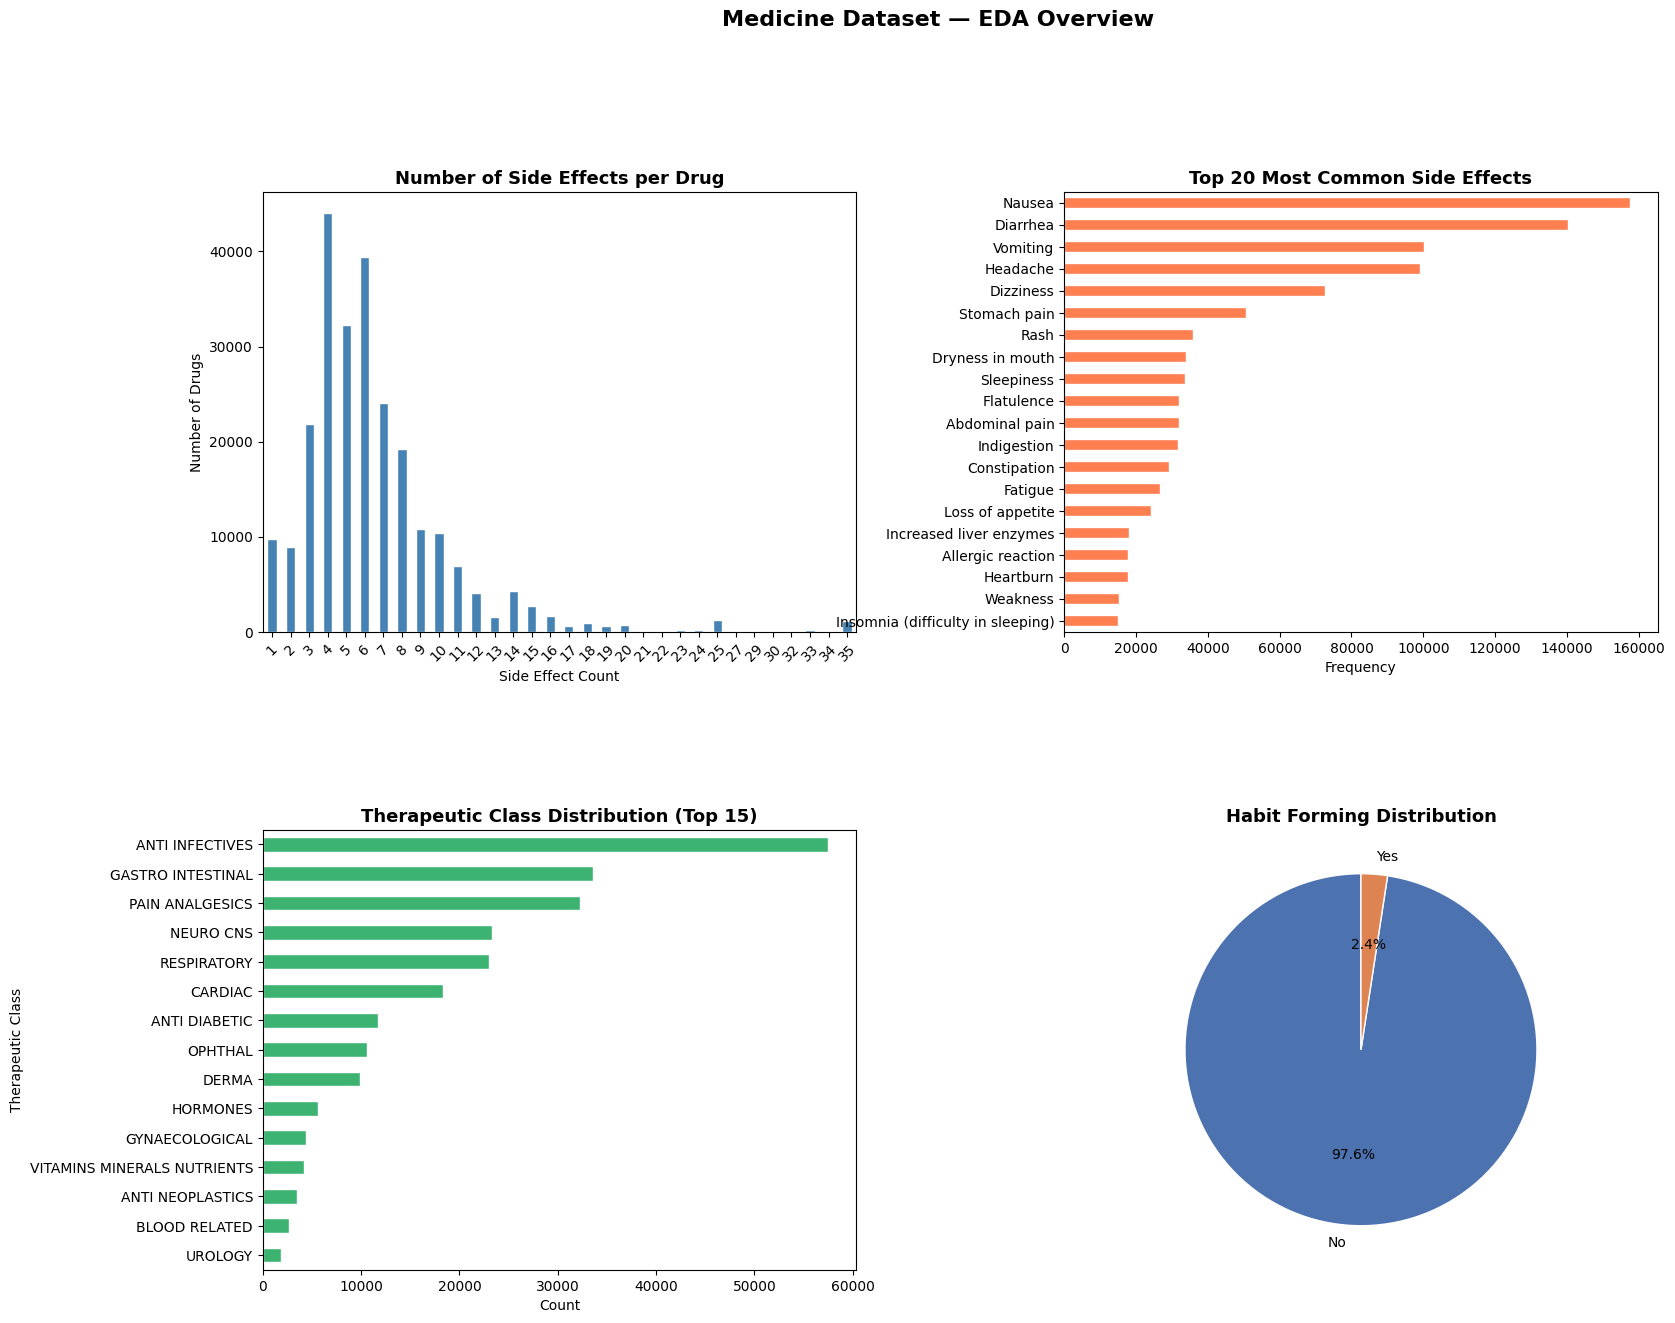


EDA plot saved.


In [2]:
# ============================================================
# 01_eda.ipynb | CELL 3 — Exploratory Data Analysis (EDA)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# ── Load Data ─────────────────────────────────────────────────
DATA_PATH = "/teamspace/studios/this_studio/data/drug_reviews/medicine_dataset.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)

# ── Side Effect Columns (only non-100% missing) ───────────────
se_cols  = [f"sideEffect{i}" for i in range(35)]   # 0-34 only
use_cols = [f"use{i}" for i in range(5)]

# ── 1. Number of Side Effects per Drug ───────────────────────
df["se_count"] = df[se_cols].notna().sum(axis=1)

print("Side Effect Count Stats:")
print(df["se_count"].describe().round(2))
print(f"\nDrugs with 0  side effects : {(df['se_count']==0).sum():,}")
print(f"Drugs with 1-5 side effects : {((df['se_count']>=1) & (df['se_count']<=5)).sum():,}")
print(f"Drugs with 6+ side effects  : {(df['se_count']>=6).sum():,}")

# ── 2. Top 20 Most Common Side Effects ───────────────────────
all_se = pd.Series(df[se_cols].values.ravel()).dropna()
top_se = all_se.value_counts().head(20)

print(f"\nTop 20 Side Effects:")
print(top_se.to_string())

# ── 3. Therapeutic Class Distribution ────────────────────────
print(f"\nTherapeutic Class (Top 15):")
print(df["Therapeutic Class"].value_counts().head(15).to_string())

# ── 4. Habit Forming Distribution ────────────────────────────
print(f"\nHabit Forming:")
print(df["Habit Forming"].value_counts().to_string())

# ── 5. Plots ──────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# Plot 1 — Side Effect Count Distribution
ax1 = fig.add_subplot(gs[0, 0])
df["se_count"].value_counts().sort_index().plot(
    kind="bar", ax=ax1, color="steelblue", edgecolor="white"
)
ax1.set_title("Number of Side Effects per Drug", fontsize=13, fontweight="bold")
ax1.set_xlabel("Side Effect Count")
ax1.set_ylabel("Number of Drugs")
ax1.tick_params(axis="x", rotation=45)

# Plot 2 — Top 20 Side Effects
ax2 = fig.add_subplot(gs[0, 1])
top_se.sort_values().plot(
    kind="barh", ax=ax2, color="coral", edgecolor="white"
)
ax2.set_title("Top 20 Most Common Side Effects", fontsize=13, fontweight="bold")
ax2.set_xlabel("Frequency")

# Plot 3 — Therapeutic Class (Top 15)
ax3 = fig.add_subplot(gs[1, 0])
df["Therapeutic Class"].value_counts().head(15).sort_values().plot(
    kind="barh", ax=ax3, color="mediumseagreen", edgecolor="white"
)
ax3.set_title("Therapeutic Class Distribution (Top 15)", fontsize=13, fontweight="bold")
ax3.set_xlabel("Count")

# Plot 4 — Habit Forming
ax4 = fig.add_subplot(gs[1, 1])
df["Habit Forming"].value_counts().plot(
    kind="pie", ax=ax4, autopct="%1.1f%%",
    colors=["#4C72B0", "#DD8452", "#55A868"],
    startangle=90, wedgeprops={"edgecolor": "white"}
)
ax4.set_title("Habit Forming Distribution", fontsize=13, fontweight="bold")
ax4.set_ylabel("")

plt.suptitle("Medicine Dataset — EDA Overview", fontsize=16, fontweight="bold", y=1.01)
plt.savefig("/teamspace/studios/this_studio/data/eda_overview.png",
            bbox_inches="tight", dpi=150)
plt.show()
print("\nEDA plot saved.")

Severity Label Distribution:
           Count      %
severity               
MILD      126918  51.13
CRITICAL   66413  26.76
MODERATE   54887  22.11

Final DataFrame shape : (248218, 9)

Sample rows:
                       name                                                                                                                                                         all_side_effects                           all_uses  se_count Chemical Class Habit Forming Therapeutic Class Action Class  severity
0  augmentin 625 duo tablet                                                                                                                                               Vomiting, Nausea, Diarrhea  Treatment of Bacterial infections         3            NaN            No   ANTI INFECTIVES          NaN      MILD
1       azithral 500 tablet                                                                                                                               Vomiting, Nausea, Abdo

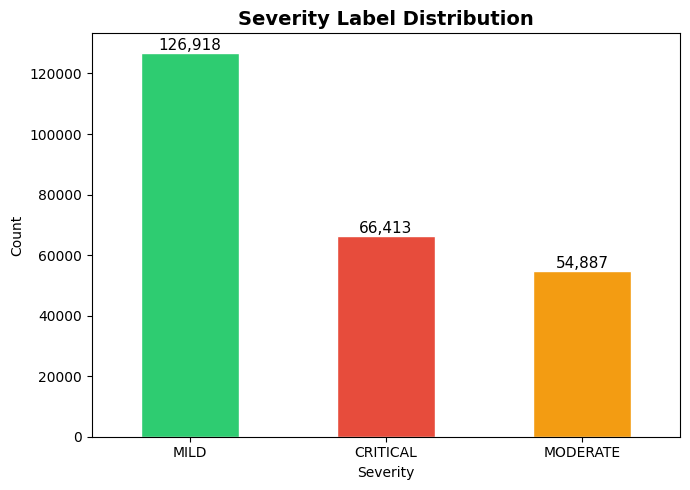

Plot saved.


In [3]:
# ============================================================
# 01_eda.ipynb | CELL 4 — Feature Engineering & Severity Label
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# ── Load Data ─────────────────────────────────────────────────
DATA_PATH = "/teamspace/studios/this_studio/data/drug_reviews/medicine_dataset.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)

# ── Step 1: Consolidate Side Effects → single text column ─────
se_cols  = [f"sideEffect{i}" for i in range(35)]   # drop 35-41 (100% missing)
use_cols = [f"use{i}" for i in range(5)]

df["all_side_effects"] = df[se_cols].apply(
    lambda row: ", ".join(row.dropna().astype(str).str.strip()), axis=1
)

# ── Step 2: Consolidate Uses → single text column ─────────────
df["all_uses"] = df[use_cols].apply(
    lambda row: ", ".join(row.dropna().astype(str).str.strip()), axis=1
)

# ── Step 3: Side Effect Count ─────────────────────────────────
df["se_count"] = df[se_cols].notna().sum(axis=1)

# ── Step 4: Severity Label Engineering ───────────────────────
CRITICAL_KEYWORDS = [
    "cardiac", "heart", "liver", "hepatic", "kidney", "renal",
    "fatal", "death", "coma", "stroke", "seizure", "convulsion",
    "anaphylaxis", "anaphylactic", "respiratory", "paralysis",
    "hemorrhage", "bleeding", "toxic", "failure", "necrosis",
    "agranulocytosis", "thrombosis", "sepsis", "shock",
    "arrhythmia", "fibrillation", "infarction", "embolism",
    "pancreatitis", "jaundice", "encephalopathy"
]

MODERATE_KEYWORDS = [
    "allergic reaction", "swelling", "oedema", "edema",
    "depression", "anxiety", "hallucination", "psychosis",
    "inflammation", "infection", "fever", "hypertension",
    "hypotension", "tachycardia", "bradycardia", "palpitation",
    "muscle cramp", "tremor", "peripheral neuropathy"
]

def assign_severity(row):
    se_text = str(row["all_side_effects"]).lower()
    habit   = str(row["Habit Forming"]).strip().lower()
    count   = row["se_count"]

    # CRITICAL — any life-threatening keyword
    if any(kw in se_text for kw in CRITICAL_KEYWORDS):
        return "CRITICAL"

    # MODERATE — habit forming OR significant count OR moderate keywords
    if habit == "yes" or count >= 10 or any(kw in se_text for kw in MODERATE_KEYWORDS):
        return "MODERATE"

    # MILD — everything else
    return "MILD"

df["severity"] = df.apply(assign_severity, axis=1)

# ── Step 5: Severity Distribution ────────────────────────────
print("Severity Label Distribution:")
dist = df["severity"].value_counts()
pct  = (dist / len(df) * 100).round(2)
print(pd.DataFrame({"Count": dist, "%": pct}).to_string())

# ── Step 6: Keep Only Needed Columns ─────────────────────────
df_clean = df[[
    "name",
    "all_side_effects",
    "all_uses",
    "se_count",
    "Chemical Class",
    "Habit Forming",
    "Therapeutic Class",
    "Action Class",
    "severity"
]].copy()

print(f"\nFinal DataFrame shape : {df_clean.shape}")
print(f"\nSample rows:")
print(df_clean.head(3).to_string())

# ── Step 7: Save Engineered Dataset ──────────────────────────
SAVE_PATH = "/teamspace/studios/this_studio/data/drug_reviews/medicine_engineered.csv"
df_clean.to_csv(SAVE_PATH, index=False)
print(f"\nSaved engineered dataset → {SAVE_PATH}")

# ── Step 8: Severity Distribution Plot ───────────────────────
plt.figure(figsize=(7, 5))
colors = {"CRITICAL": "#e74c3c", "MODERATE": "#f39c12", "MILD": "#2ecc71"}
ax = df["severity"].value_counts().plot(
    kind="bar",
    color=[colors[s] for s in df["severity"].value_counts().index],
    edgecolor="white"
)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.title("Severity Label Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Severity")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/teamspace/studios/this_studio/data/severity_distribution.png", dpi=150)
plt.show()
print("Plot saved.")